## **一、S4-02｜把速度场接进图文生成**

S4-01 用已知的二维速度场，从随机点走到了双高斯。本课把点换成图像 latent，把解析场换成可训练的 Plain DiT。要回答三个问题。图像与文字在哪里汇合？同一个网络输出怎样同时供 MSE 和 ODE 使用？怎样用独立证据区分「代码通了」「学到了条件」和「生成看起来对」？

本课承接 [S4-01 的路径与 ODE](S4_01_FlowMatching原理与ODE采样.ipynb)、[S2 的 DiT](S2_第3周_图标数据与潜空间DiT基础.ipynb) 与 [S3 的文本条件和 CFG](S3_文本条件CFG与可信评测.ipynb)。运行顺序是先看四类图标，再验收编码器和模型形状，随后运行固定监督、随机训练、恢复和采样。最后合上参考代码，亲手实现两个核心函数。

### **1. 先看本课要生成什么**

给定 `a blue square`，希望白底上出现蓝色方形。把提示改成 `a red square`，保持初始噪声相同，观察颜色是否随文字变而形状仍对。图标的中心和尺寸有变化，描述只指定颜色与形状。四个组合都见于训练，因此这里测的是熟悉提示下的条件利用，以及对未见几何实例的速度预测表现。

| 数据 | 规模 | 作用 |
| --- | --- | --- |
| 学习训练集 | 64 张 64px 图，每类 16 张 | 从零训练教学 DiT |
| 学习留出集 | 32 张 64px 图，每类 8 张 | 固定噪声与时间对照，检查重建和评分规则 |
| 组件探针 | 1 张 256px 图 | 实测 VAE 形状、缩放与 patch 往返 |
| 生成起点 | 每条提示 4 个固定噪声种子 | 配对比较空条件、Euler、Heun、CFG |

每种颜色和形状共用各自集合内的同一组尺寸和位置，避免模型靠位置区分文字。训练与留出的几何参数组及渲染像素哈希互斥。全部合成图、latent、token、模型和恢复快照只在本课内存中创建。若以后需要保留这类资产，放到独立的 `artifacts/learning/s4_02/`，并标注课程、渲染种子、划分和组件身份。

使用已有项目 Python 内核和本地 `notebook`、`latent`、`conditioning` 依赖。执行顺序从上到下。冻结权重的加载路径来自固定身份文件，缺失或哈希不符时停止。本课使用 CPU FP32 和最多四个 PyTorch CPU 线程。MPS 或 CUDA 上需重新验算精度、有限值和恢复容差，尤其不能把本课 CPU 的精确恢复结论直接搬过去。

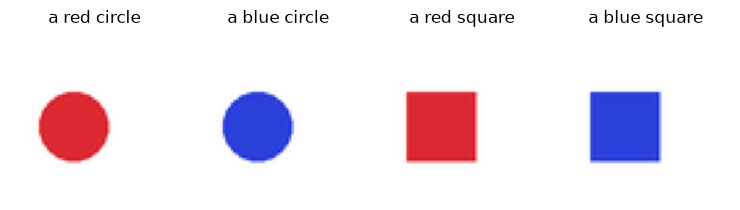

Python 3.12.14 | PyTorch 2.14.1 | CPU FP32
train=64 | val=32 | shared image hashes=0


In [1]:
import hashlib
import io
import os
import sys
from collections.abc import Callable
from pathlib import Path
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import torch
from PIL import Image, ImageDraw
from torch import Tensor, nn

from minigen.autoencoders.frozen import FrozenVAE
from minigen.conditioning.text import FrozenTextEncoder

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/models/sdxl_vae.json").is_file()
)
os.environ["HF_HUB_OFFLINE"] = "1"
torch.set_num_threads(min(4, torch.get_num_threads()))
captions = ["a red circle", "a blue circle", "a red square", "a blue square"]
palette = [(219, 41, 50), (43, 64, 218)]
grid = [
    (cx, cy, size)
    for cx in (24, 28, 32, 36, 40)
    for cy in (24, 28, 32, 36, 40)
    for size in (26, 30, 34, 38)
]
permutation = np.random.default_rng(40201).permutation(len(grid))
train_geo = [grid[i] for i in permutation[:16]]
val_geo = [grid[i] for i in permutation[16:24]]
assert set(train_geo).isdisjoint(val_geo)


def render_icon(
    label: int,
    geometry: tuple[int, int, int],
    resolution: int = 64,
) -> Tensor:
    """渲染一个图标，返回 [3,h,w]，范围 [-1,1]。"""
    cx, cy, size = geometry
    factor = resolution * 2 / 64
    image = Image.new("RGB", (resolution * 2,) * 2, "white")
    draw = ImageDraw.Draw(image)
    box = tuple(
        round(x * factor) for x in (cx - size / 2, cy - size / 2, cx + size / 2, cy + size / 2)
    )
    (draw.ellipse if label < 2 else draw.rectangle)(box, fill=palette[label % 2])
    pixels = np.array(image.resize((resolution,) * 2, Image.Resampling.LANCZOS))
    return torch.from_numpy(pixels).permute(2, 0, 1).float() / 127.5 - 1


train_x = torch.stack([render_icon(j, g) for j in range(4) for g in train_geo])
val_x = torch.stack([render_icon(j, g) for j in range(4) for g in val_geo])
train_y = torch.arange(4).repeat_interleave(len(train_geo))
val_y = torch.arange(4).repeat_interleave(len(val_geo))
train_hashes = {hashlib.sha256(x.numpy().tobytes()).digest() for x in train_x}
val_hashes = {hashlib.sha256(x.numpy().tobytes()).digest() for x in val_x}
assert len(train_hashes) == 64 and len(val_hashes) == 32 and train_hashes.isdisjoint(val_hashes)

fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.1))
for j, ax in enumerate(axes):
    ax.imshow((train_x[j * 16].permute(1, 2, 0) + 1) / 2)
    ax.set_title(captions[j])
    ax.axis("off")
fig.tight_layout()
plt.show()
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | CPU FP32")
print(f"train={len(train_x)} | val={len(val_x)} | shared image hashes=0")

### **2. 从两路输入到一张图**

| 阶段 | 图像或 latent 一路 | 文本一路 | 在哪里汇合 |
| --- | --- | --- | --- |
| 训练前准备 | 图像归一化至 $[-1,1]$，冻结 VAE 编码并缩放 | Caption 经冻结 CLIP 得到 token 和有效位 | 两者通过样本与 Caption 的配对索引一起进入批次 |
| 一步训练 | 从干净 latent $z$、噪声 $\epsilon$ 与时间 $t$ 构造 $z_t$ | 通常读配对 Caption，有一定概率读真实空串 | DiT 的图像 query 读取文本 key/value，输出同形速度 |
| 一次采样 | 起点是随机 latent。反复根据速度更新，终点再解码 | 提示只编码一次，各步复用。需要 CFG 时也复用空串特征 | 每次场求值都使用当时的 $z_t,t$，与相同的文本条件 |

正式路线将图像与描述来源换成经过审计的 OpenClipart 与配对 Caption，并在 256px 上比较架构。教学实验保留相同的接口语义，使用更小的 latent 和主干来把问题拆开。OpenClipart 的质量、数据划分和正式模型仍有自己的验收流程。[MiniGen v2 重构规划](../MiniGen2重构规划.md)

## **二、冻结 VAE 与 CLIP｜先校对数据的单位**

### **1. 为什么 latent 要乘 scale，解码要除**

给定归一化图像 $x$，VAE Encoder 提供潜变量后验 $q_\phi(z_{\rm raw}\mid x)$。本课取 `posterior.mode()` 作为固定编码。SDXL VAE 的对角高斯后验在均值处取得众数。固定编码让每次访问同一图片得到相同监督，代价是忽略后验的不确定性。用组件配置中的因子 $\alpha_{\rm vae}$ 变换到训练所用坐标。

$$z=\alpha_{\rm vae}\,z_{\rm raw},\qquad \widehat x=\mathrm{Dec}\left(z/\alpha_{\rm vae}\right)$$

正因子既缩放均值，也让方差乘 $\alpha_{\rm vae}^2$。它并不会保证任意数据集的 latent 均值为零或标准差为一。训练和采样共用缩放后的坐标系，目标中的高斯噪声也在这个坐标系里。到 VAE Decoder 门口只逆缩放一次。

> **手算一个坐标。** 若原始后验均值是 $2$，因子为 $0.13025$，缓存存 $0.26050$。解码前除以 $0.13025$ 恢复 $2$。把 $0.26050$ 直接交给 Decoder 就少了一次逆变换。原始解码像素可能超出 $[-1,1]$，展示时再映射到 $[0,1]$ 并裁剪。

### **2. 文本条件是一串 token 特征**

CLIP Text Encoder 返回最后一层 token 特征 $C$，每行附有效位 $M$。一段最多 77 个位置，其中两个给 BOS 和 EOS。空串仍经同一编码器得到 BOS 和 EOS 的特征与 mask。它表示训练中约定的空条件。固定容量超长会明确报错。本课省去整个批次都不使用的尾部，从 77 位置裁到当前词表的最大有效长度。某条较短文本仍要用自己的 mask 屏蔽剩余位置。对齐键是样本的描述索引，调整图像批次顺序时必须同步调整文字条件。

| 张量 | 256px 目标链路 | 本课 64px 图标 | 含义 |
| --- | --- | --- | --- |
| $x$ | `[b,3,256,256]` | `[b,3,64,64]` | VAE 输入像素 |
| $z,\epsilon,z_t,u,v_\theta$ | `[b,4,32,32]` | `[b,4,8,8]` | 缩放坐标系里的状态或速度 |
| 时间 $t$ | `[b]` | `[b]` | 每个图像一个时刻 |
| CLIP 特征 $C$ | `[b,L,512]` | `[b,L,512]` | Token hidden states |
| 有效位 $M$ | `[b,L]` | `[b,L]` | bool，True 表示可被读取 |

下面用项目已有的本地加载器校验文件哈希。一次真实的 256px 往返用于核对 4 通道、8 倍空间压缩与像素形状。训练缓存使用 64px，直接在内存中从图像计算。展示重建也能把 VAE 自己造成的模糊与生成模型造成的问题分开。[冻结 VAE 接口](src/minigen/autoencoders/frozen.py) · [冻结文本接口](src/minigen/conditioning/text.py) · [固定 VAE 组件](https://huggingface.co/madebyollin/sdxl-vae-fp16-fix/tree/207b116dae70ace3637169f1ddd2434b91b3a8cd)

/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1106 03:33:37.430000 83340 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 12609.22it/s]

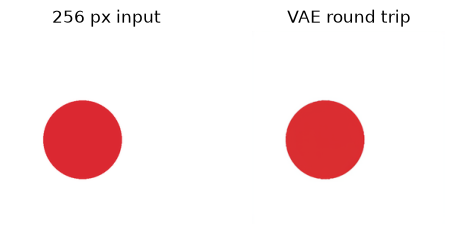

VAE revision=207b116dae70ace3637169f1ddd2434b91b3a8cd | scale=0.13025
CLIP revision=3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268 | valid tokens=[5, 5, 5, 5, 2]
256 latent=(1, 4, 32, 32); train latent=(64, 4, 8, 8)
text (5, 77, 512) -> (5, 5, 512); cache in RAM
train latent mean=0.2855 std=1.4042
components + cache: 12.24 s


In [2]:
stamp = perf_counter()
vae = FrozenVAE.load(root, root / "configs/models/sdxl_vae.json")
text_encoder = FrozenTextEncoder.load(root, root / "configs/models/clip_text.json", max_chunks=1)
for component_model in (vae.model, text_encoder.model):
    assert not component_model.training
    assert all(not p.requires_grad for p in component_model.parameters())

text_full, mask_full, lengths = text_encoder.encode([*captions, ""])
assert text_full.shape == (5, 77, 512)
assert mask_full.dtype == torch.bool and lengths[-1] == 0 and mask_full[-1].sum() == 2
assert torch.equal(mask_full, torch.arange(77)[None] < torch.tensor(lengths)[:, None] + 2)
# 只去掉所有行都无效的尾部；每一行自己的 mask 仍然保留。
token_count = max(lengths) + 2
text_bank = text_full[:, :token_count].contiguous()
mask_bank = mask_full[:, :token_count].contiguous()

probe = render_icon(0, train_geo[0], 256)[None]
z_256 = vae.encode(probe)
recon_256 = vae.decode(z_256)
assert z_256.shape == (1, 4, 32, 32) and recon_256.shape == (1, 3, 256, 256)
with torch.no_grad():
    probe_mode = vae.model.encode(probe).latent_dist.mode()
torch.testing.assert_close(z_256 / vae.scale, probe_mode)
train_z = torch.cat([vae.encode(x) for x in train_x.split(8)])
val_z = torch.cat([vae.encode(x) for x in val_x.split(8)])
assert train_z.shape == (64, 4, 8, 8) and val_z.shape == (32, 4, 8, 8)
assert not train_z.requires_grad and not text_bank.requires_grad
assert all(torch.isfinite(x).all() for x in (train_z, val_z, text_bank, recon_256))

fig, axes = plt.subplots(1, 2, figsize=(5, 2.4))
for ax, x, name in zip(
    axes, (probe[0], recon_256[0]), ("256 px input", "VAE round trip"), strict=True
):
    ax.imshow(((x.permute(1, 2, 0) + 1) / 2).clamp(0, 1))
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()
print(f"VAE revision={vae.identity['revision']} | scale={vae.scale}")
print(
    f"CLIP revision={text_encoder.identity['revision']} | valid tokens={mask_full.sum(1).tolist()}"
)
print(f"256 latent={tuple(z_256.shape)}; train latent={tuple(train_z.shape)}")
print(f"text {tuple(text_full.shape)} -> {tuple(text_bank.shape)}; cache in RAM")
print(f"train latent mean={train_z.mean():.4f} std={train_z.std(unbiased=False):.4f}")
print(f"components + cache: {perf_counter() - stamp:.2f} s")

## **三、Plain DiT｜一个图像流怎样读取文字**

### **1. 跟一次张量前向**

Plain DiT 的主序列由图像 token 组成。对每个图像 patch，先把 $p\times p\times c$ 个数拼起来，再做线性投影和加二维位置编码。图像 self-attention 更新图像 token 间的关系。text cross-attention 以图像 token 为 query，以文本为 key/value。文本塔被冻结，DiT 内部的 Q、K/V、输出投影仍参与训练。最后速度头将每个图像 token 映射回每个 patch 的速度值，再按空间位置还原。

| 操作 | 256px 时 | 教学 64px 时 |
| --- | --- | --- |
| patch 尺寸 $p$ | $2$ | $2$ |
| 图像序列长 $n=(h_z/p)(w_z/p)$ | $256$ | $16$ |
| 展平单个 patch | $4\times2\times2=16$ | $16$ |
| Patch Embedding | `[b,256,d]` | `[b,16,96]` |
| Velocity Head | `[b,256,16]` | `[b,16,16]` |
| Unpatchify | `[b,4,32,32]` | `[b,4,8,8]` |

> **为什么不用 256px 做整轮训练？** 图像 token 从 16 到 256 增加 16 倍。显式 self-attention 的每头分数矩阵从 $16^2$ 变成 $256^2$，元素数量增加 256 倍。总运行时间还包括线性层、文本注意力、设备内核等开销，不能直接按分数矩阵的比例换算。这里做真实 256px 形状探针，再把训练预算集中在可复验的 64px 闭环。

设头数为 $a$，每头宽度为 $d_h=d/a$。Cross-Attention 的 $Q$ 形状为 `[b,a,n,d_h]`，$K,V$ 为 `[b,a,L,d_h]`。因此 logits 是 `[b,a,n,L]`。在文本轴 softmax **之前**，把无效 token 的分数排除，概率才会在有效 token 间归一化。加权输出为 `[b,a,n,d_h]`，合并头后仍是一条图像序列。下一课会比较这种单向读取与 Joint Attention 中两种 token 一起更新的区别。

### **2. 时间调制、零初始化和源码对应**

时间嵌入 $e(t)$ 经过 MLP 产生逐样本的缩放 $\gamma$、平移 $\beta$ 与残差门 $g$。对某个子层 $F$，可把调制写成

$$X'=X+g(t)\odot F\left[(1+\gamma(t))\odot\mathrm{LN}(X)+\beta(t)\right]$$

三个向量从 `[b,d]` 广播到所有图像 token。初始门为零时，该残差路径近似从恒等映射起步。S3 教学实现给 cross-attention 也加了单独的零门。输出头本身同时从零开始。设最后特征为 $H$，输出为 $HW^\top+b$。当 $W=0$ 时，损失对 $H$ 的梯度含 $W$，首步可为零，但对 $W$ 的梯度仍含 $H$，能先更新输出头。随着 head 和门打开，再检查 cross-attention 的 K/V 梯度。只看初始化阶段的「换文本输出一致」无法判断条件链路是否断了。

下面按唯一 tag 与 SHA-256 显式加载已有的 S2 DiT、S3 条件 DiT 和 CFG 参考单元。只执行这三个定义单元，结构继承教学代码，实例随机初始化。原输出曾用于噪声预测，此处用全新的模型按速度标签训练，因此输出语义由新目标定义。连续 $t$ 在 $[0,1]$。进入复用的正弦嵌入时统一乘 $1000$，只是本课选择的特征刻度，采样积分步长仍是 $1/N$。官方 DiT 与本课的条件方式并不完全相同，官方工作包含类别条件等多种设计。[DiT 原论文](https://arxiv.org/abs/2212.09748v2)

In [3]:
reference_sources = [
    (
        "S2_第3周_图标数据与潜空间DiT基础.ipynb",
        "dit_reference",
        "1add9941d358c3d50aef18cb6cc0f3b9dd37568befcea0499d8bc308b79a8669",
    ),
    (
        "S3_文本条件CFG与可信评测.ipynb",
        "conditional_reference",
        "6e404f6595aa83e3e3ad0b3c802cdbe9e74484dd6f730a7d939117fd6fd20a24",
    ),
    (
        "S3_文本条件CFG与可信评测.ipynb",
        "cfg_reference",
        "87ff5a1704acc2370e9a41cda7e81019479030b7c5fc23fd97f45942aa6fd4cf",
    ),
]
reference_namespace = {}
for filename, tag, expected_hash in reference_sources:
    source_nb = nbformat.read(root / "docs/learning" / filename, as_version=4)
    matching = [
        c.source
        for c in source_nb.cells
        if c.cell_type == "code" and tag in c.metadata.get("tags", ())
    ]
    assert len(matching) == 1
    assert hashlib.sha256(matching[0].encode()).hexdigest() == expected_hash
    exec(compile(matching[0], f"{filename}:{tag}", "exec"), reference_namespace)

ReferenceDiT = reference_namespace["ConditionalDiTReference"]
patchify = reference_namespace["patchify_reference"]
unpatchify = reference_namespace["unpatchify_reference"]
combine_cfg = reference_namespace["cfg_reference"]
patch_256 = patchify(z_256, 2)
assert patch_256.shape == (1, 256, 16)
torch.testing.assert_close(unpatchify(patch_256, 4, 32, 32, 2), z_256)
model_args = dict(depth=2, hidden=96, heads=4, channels=4, size=8, patch=2, text_width=512)


def new_run() -> tuple[nn.Module, torch.optim.Optimizer]:
    """创建随机初始化教学主干和 AdamW，固定初始化种子。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(40203)
        model = ReferenceDiT(**model_args)
    return model, torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)


def velocity(
    model: nn.Module,
    z_t: Tensor,
    time: Tensor,
    text: Tensor,
    valid: Tensor,
) -> Tensor:
    """将连续时间送入旧 DiT 的正弦嵌入刻度，返回同形速度。"""
    return model(z_t, 1000.0 * time, text, valid)


parameter_probe, _ = new_run()
with torch.no_grad():
    zero_head = velocity(
        parameter_probe, train_z[:1], torch.tensor([0.5]), text_bank[:1], mask_bank[:1]
    )
assert zero_head.shape == (1, 4, 8, 8) and torch.count_nonzero(zero_head).item() == 0
print(f"256 probe patch tensor {tuple(patch_256.shape)}")
print(f"trainable DiT params = {sum(p.numel() for p in parameter_probe.parameters()):,}")
del parameter_probe

256 probe patch tensor (1, 256, 16)
trainable DiT params = 609,714


## **四、训练｜先检查梯度，再检查泛化**

### **1. 让监督和采样用同一种速度**

对训练 latent $z$ 采样同形独立高斯 $\epsilon$，每张图独立采 $t\sim U[0,1]$。直线位置为 $z_t=\epsilon+t(z-\epsilon)$，对 $t$ 求导得到目标速度 $u=z-\epsilon$。这里只抽一个时刻就能构造监督。给定 $z_t,t,C$ 后，模型用平方回归逼近不可见端点对应的条件平均速度，见 S4-01 的证明。

$$\mathcal L=\frac1{b\,c_z h_z w_z}\sum_{i,j,k,l}\left(v_{\theta,ijkl}(z_t,t,C,M)-u_{ijkl}\right)^2$$

对每个 latent 元素取均值，固定图像形状下各样本等权。文本 padding 只作用于注意力，图像 loss 不拿文本 token 数归一化。训练以概率 $0.1$ 把 **整条文本及其 mask** 换成真实空条件，图像、噪声、时间和速度目标都保留。这样同一个 DiT 能收到有文本和无文本两类监督。

> **手算 latent 一个格子。** 若 $\epsilon=1.0$、$z=-0.5$、$t=0.25$，路径点为 $0.625$，速度为 $-1.5$。若模型预测 $-1.0$，这一格的平方误差是 $0.25$。保持预测速度 $-1.5$ 走完一单位时间，从 $1.0$ 恰好到 $-0.5$。把标签写成 $\epsilon-z$ 会走反方向。

实现中将时间显式变成 `[b,1,1,1]`。先检验 $t=0,1$ 与速度符号。MSE 在 FP32 计算并拒绝异形输入，反向前检查有限值，AdamW 更新前做梯度裁剪。优化器只收到 DiT 参数。学习代码中使用即时随机批次和简单固定学习率，便于直接检查一次更新。[Flow Matching 原论文](https://arxiv.org/abs/2210.02747v2)

In [ ]:
def make_pair(
    clean: Tensor,
    noise: Tensor,
    time: Tensor,
) -> tuple[Tensor, Tensor]:
    """在 [b,c,h,w] 上构造路径点与速度标签。"""
    return torch.lerp(noise, clean, time[:, None, None, None]), clean - noise


def mse_reference(
    predicted: Tensor,
    target: Tensor,
) -> Tensor:
    """检查同形后，对所有速度元素取 FP32 均方误差。"""
    if predicted.shape != target.shape:
        raise ValueError("velocity prediction/target shapes must match")
    return (predicted.float() - target.float()).square().mean()


def train_step(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    batch: tuple[Tensor, Tensor, Tensor, Tensor, Tensor],
) -> Tensor:
    """执行一次教学更新，保留更新前的标量损失。"""
    z_t, t, u, text, valid = batch
    optimizer.zero_grad(set_to_none=True)
    loss = mse_reference(velocity(model, z_t, t, text, valid), u)
    if not torch.isfinite(loss):
        raise RuntimeError("nonfinite velocity loss")
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
    optimizer.step()
    return loss.detach()


def draw_batch(
    rng: torch.Generator,
    batch_size: int,
) -> tuple[Tensor, Tensor, Tensor, Tensor, Tensor]:
    """每次重抽样本、时间、噪声和是否换成空条件。"""
    i = torch.randint(len(train_z), (batch_size,), generator=rng)
    clean = train_z[i]
    noise = torch.randn(clean.shape, generator=rng)
    t = torch.rand(batch_size, generator=rng)
    dropped = torch.rand(batch_size, generator=rng) < 0.10
    condition_ids = torch.where(dropped, len(captions), train_y[i])
    z_t, u = make_pair(clean, noise, t)
    return z_t, t, u, text_bank[condition_ids], mask_bank[condition_ids]


z_clean = train_z[[0, 16]]
eps_probe = torch.full_like(z_clean, 0.5)
z_endpoints, label_endpoints = make_pair(z_clean, eps_probe, torch.tensor([0.0, 1.0]))
torch.testing.assert_close(z_endpoints[0], eps_probe[0])
torch.testing.assert_close(z_endpoints[1], z_clean[1])
torch.testing.assert_close(z_endpoints[0] + label_endpoints[0], z_clean[0])
assert label_endpoints.shape == z_clean.shape and not label_endpoints.requires_grad
print("checked: per-example endpoints, velocity sign and shape")

checked: per-example endpoints, velocity sign and shape


### **2. 固定监督拟合先回答代码有没有更新**

固定 8 张训练图，每类两张。固定对应的噪声和时间，反复优化相同的 8 条速度标签。由于初始化输出为零，首步 MSE 可视为零速度基线。记录第一个更新的速度头梯度以及训练后段的 cross K/V 梯度。若固定目标都无法拟合，应先排查形状、尺度、冻结和反向路径，再增加训练预算。

固定监督中的一对端点被模型重复看到。即使这批目标几乎完全记住，也不能据此判断对新起点的 ODE 轨迹会怎样。下一格创建同样初始化种子的 **新** 模型和优化器，重新开始随机训练。

In [5]:
fixed_model, fixed_optimizer = new_run()
fit_i = torch.tensor([0, 1, 16, 17, 32, 33, 48, 49])
fit_rng = torch.Generator().manual_seed(40202)
fit_noise = torch.randn(train_z[fit_i].shape, generator=fit_rng)
fit_t = torch.rand(len(fit_i), generator=fit_rng)
fit_z, fit_u = make_pair(train_z[fit_i], fit_noise, fit_t)
fit_text, fit_mask = text_bank[train_y[fit_i]], mask_bank[train_y[fit_i]]
fixed_batch = (fit_z, fit_t, fit_u, fit_text, fit_mask)
initial = train_step(fixed_model, fixed_optimizer, fixed_batch).item()
assert fixed_model.output.weight.grad.abs().sum().item() > 0
assert fixed_model.cross[0].kv.weight.grad.abs().sum().item() == 0
for _ in range(159):
    train_step(fixed_model, fixed_optimizer, fixed_batch)
with torch.no_grad():
    final_fixed = mse_reference(velocity(fixed_model, fit_z, fit_t, fit_text, fit_mask), fit_u)
late_cross_gradient = fixed_model.cross[0].kv.weight.grad.norm().item()
assert late_cross_gradient > 0.0 and torch.isfinite(final_fixed)
print(f"fixed batch | 160 updates | MSE {initial:.5f} -> {final_fixed:.5f}")
print(
    f"first update: head nonzero, cross K/V zero | later cross grad norm={late_cross_gradient:.6g}"
)
del fixed_model, fixed_optimizer

fixed batch | 160 updates | MSE 3.06988 -> 0.04474
first update: head nonzero, cross K/V zero | later cross grad norm=0.00450532


### **3. 随机训练与独立留出对照**

| 设置 | 本课固定值 |
| --- | --- |
| DiT | 2 层，hidden 96，4 heads，patch 2，随机初始化 seed 40203 |
| 更新 | AdamW，学习率 $3\times10^{-4}$，weight decay $0.01$，梯度范数上限 1 |
| 教学训练 | 2400 次更新，batch 16，带放回抽样，训练 RNG seed 40204 |
| 随机监督 | 每次重抽样本、噪声、均匀时间和整条文本丢弃 |
| 验证 | 32 张未见几何图，固定 RNG seed 40205，每张在 $t=0.2,0.5,0.8$ 评估 |
| 检查点选择 | 用预设末步采样。验证曲线用于理解训练行为 |

在同一张留出图上固定 $z_t,t,u$，只把描述在正确、只换颜色、只换形状、空串四种条件间切换。正确条件的 MSE 更低支持「文字对该批回归有帮助」。在 $t$ 小时，输入更接近噪声，图像本身给的信号较弱。到 $t$ 大时，$z_t$ 自己已含有较多图像信息。各时段的目标难度不相同，因此逐时刻报告。

除了初始零速度，还计算 **训练集对角高斯矩基线**。假设某个 latent 坐标的 $Z$ 可粗略用均值 $\mu$、方差 $\sigma^2$ 的高斯近似，忽略文本和坐标间相关性。按 S4-01 的联合高斯条件均值，$\mathbb E[U]=\mu$，$\operatorname{Var}(Z_t)=(1-t)^2+t^2\sigma^2$，$\operatorname{Cov}(U,Z_t)=t\sigma^2-(1-t)$，得到

$$v_{\mathrm{mom}}(z_t,t)=\mu+\frac{t\sigma^2-(1-t)}{(1-t)^2+t^2\sigma^2}(z_t-t\mu)$$

$\mu,\sigma^2$ 只从训练 latent 估计。即便一个模型只学到高斯式的平均收缩和展开，也可能比零预测 MSE 低。加入这一基线让读者看到简单统计已经能解释多少现象。该基线用于回归对照，本课不拿它的 MSE 当生成图评分。

step  240 | train 1.5644 | val right/wrong-color/wrong-shape/empty [1.1107 1.7438 1.1202 1.1871] | 2.8s


step  480 | train 0.9339 | val right/wrong-color/wrong-shape/empty [0.9847 1.8079 0.9984 1.0483] | 5.7s


step  720 | train 0.8315 | val right/wrong-color/wrong-shape/empty [0.9367 1.9458 0.9511 0.9932] | 8.8s


step  960 | train 0.7757 | val right/wrong-color/wrong-shape/empty [0.9123 2.0889 0.9296 0.9603] | 11.8s


step 1200 | train 0.7299 | val right/wrong-color/wrong-shape/empty [0.9142 2.2381 0.9396 0.9642] | 14.6s


step 1440 | train 0.7042 | val right/wrong-color/wrong-shape/empty [0.8779 2.2784 0.9148 0.9237] | 17.7s


step 1680 | train 0.6830 | val right/wrong-color/wrong-shape/empty [0.8736 2.4061 0.9159 0.9245] | 20.6s


step 1920 | train 0.6553 | val right/wrong-color/wrong-shape/empty [0.8759 2.4492 0.9303 0.9254] | 23.4s


step 2160 | train 0.6419 | val right/wrong-color/wrong-shape/empty [0.8688 2.5518 0.928  0.9085] | 26.2s


step 2400 | train 0.6269 | val right/wrong-color/wrong-shape/empty [0.8822 2.574  0.9516 0.9288] | 29.1s


t | zero | train-moments | right | wrong color | wrong shape | empty
0.2 | 3.08640 | 1.29830 | 0.71936 | 2.34237 | 0.77253 | 0.82264
0.5 | 3.07132 | 1.64083 | 0.80130 | 2.61921 | 0.87254 | 0.81631
0.8 | 3.10479 | 1.45548 | 1.12589 | 2.76046 | 1.20963 | 1.14756


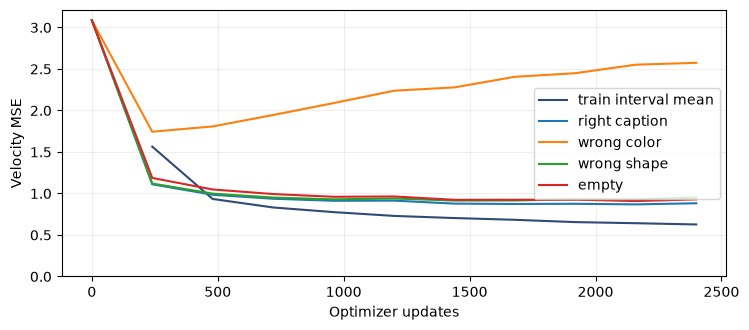

single CPU run: 2400 updates, batch 16, 29.1s


In [6]:
val_rng = torch.Generator().manual_seed(40205)
val_noise = torch.randn((3, *val_z.shape), generator=val_rng)
val_times = (0.2, 0.5, 0.8)
mu = train_z.mean(dim=0)
variance = train_z.var(dim=0, unbiased=False)


@torch.no_grad()
def validate(
    model: nn.Module,
) -> np.ndarray:
    """固定留出图、噪声和时间，对每种条件返回配对 MSE。"""
    model.eval()
    results = []
    for t, eps in zip(val_times, val_noise, strict=True):
        time = torch.full((len(val_z),), t)
        z_t, target = make_pair(val_z, eps, time)
        # 对角高斯矩基线只用训练 latent 估计的均值和方差。
        ratio = (t * variance - (1 - t)) / ((1 - t) ** 2 + t**2 * variance)
        gaussian = mu + ratio * (z_t - t * mu)
        row = [target.square().mean().item(), mse_reference(gaussian, target).item()]
        for ids in (val_y, val_y ^ 1, val_y ^ 2, torch.full_like(val_y, 4)):
            row.append(
                mse_reference(
                    velocity(model, z_t, time, text_bank[ids], mask_bank[ids]), target
                ).item()
            )
        results.append(row)
    model.train()
    return np.array(results)


model, optimizer = new_run()
train_rng = torch.Generator().manual_seed(40204)
steps, batch_size, every = 2400, 16, 240
val_log = [(0, validate(model))]
train_log, segment = [], []
stamp = perf_counter()
for step in range(1, steps + 1):
    segment.append(train_step(model, optimizer, draw_batch(train_rng, batch_size)).item())
    if step % every == 0:
        train_log.append(float(np.mean(segment)))
        segment.clear()
        metrics = validate(model)
        val_log.append((step, metrics))
        print(
            f"step {step:4d} | train {train_log[-1]:.4f} | val right/wrong-color/wrong-shape/empty "
            f"{metrics.mean(0)[2:].round(4)} | {perf_counter() - stamp:.1f}s",
            flush=True,
        )

train_seconds = perf_counter() - stamp
print("t | zero | train-moments | right | wrong color | wrong shape | empty")
for t, row in zip(val_times, val_log[-1][1], strict=True):
    print(f"{t:.1f} | " + " | ".join(f"{x:.5f}" for x in row))
fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.plot(range(every, steps + 1, every), train_log, label="train interval mean", color="#304a78")
for i, name in enumerate(("right caption", "wrong color", "wrong shape", "empty"), 2):
    ax.plot([step for step, _ in val_log], [m[:, i].mean() for _, m in val_log], label=name)
ax.set(xlabel="Optimizer updates", ylabel="Velocity MSE", ylim=(0, None))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()
print(f"single CPU run: {steps} updates, batch {batch_size}, {train_seconds:.1f}s")

## **五、工程语义审核｜mask 和恢复能否复验**

### **1. 审核已打开的条件通路**

在训练后的模型上，把空串条件的 **padding 特征** 改成大常数，保持有效 token、mask 和 latent 都不变，检查输出是否保持。空串仍有两个有效 token，因此可以单独改变 padding。再用同一个 $z_t,t$ 分别换颜色词和形状词，比较两种改动对速度的影响。前一项检查无效位置隔离，后一项检查有效条件能到达输出。哪种文字给出更准的预测，要读上一章的留出对照。

### **2. 审核恢复保存的到底是什么**

保存一次更新结束后的模型、AdamW 状态、显式数据 RNG 和 step。这里恢复第 3 步后的快照。比较连续运行与同一进程中新建对象重新加载后的第 4 步，包括下一批的状态、时间、标签和条件，及更新后的参数、AdamW 动量和 loss。使用 `BytesIO` 立即序列化，避免把仍指向活跃参数的 `state_dict` 当成独立快照。

这项检验只覆盖单进程、相同 CPU 后端、显式 RNG、无随机网络层的一步恢复。正式训练若增加数据游标、模型 dropout、EMA、LR 调度、混合精度或多个进程，还要保存对应状态与输入身份。这里只核对恢复机制的数学与状态顺序。

In [7]:
model.eval()
ids = torch.full((2,), 4)
time_probe = torch.tensor([0.2, 0.6])
z_probe = train_z[:2]
with torch.no_grad():
    empty = velocity(model, z_probe, time_probe, text_bank[ids], mask_bank[ids])
    changed_padding = torch.where(mask_bank[ids][..., None], text_bank[ids], 123.0)
    changed = velocity(model, z_probe, time_probe, changed_padding, mask_bank[ids])
    right = velocity(model, z_probe, time_probe, text_bank[[0, 0]], mask_bank[[0, 0]])
    wrong = velocity(model, z_probe, time_probe, text_bank[[1, 1]], mask_bank[[1, 1]])
    other_shape = velocity(model, z_probe, time_probe, text_bank[[2, 2]], mask_bank[[2, 2]])
torch.testing.assert_close(empty, changed, rtol=0, atol=2e-6)
assert (right - wrong).norm().item() > 0
assert all(p.grad is None for m in (vae.model, text_encoder.model) for p in m.parameters())
print(f"trained padding max delta={(empty - changed).abs().max():.2g}")
print(f"same z_t and t, change color RMS={(right - wrong).square().mean().sqrt():.5f}")

print(f"same z_t and t, change shape RMS={(right - other_shape).square().mean().sqrt():.5f}")

resume_source, resume_opt = new_run()
rng_before = torch.Generator().manual_seed(40207)
for _ in range(3):
    train_step(resume_source, resume_opt, draw_batch(rng_before, 8))
buffer = io.BytesIO()
torch.save(
    dict(
        model=resume_source.state_dict(),
        optimizer=resume_opt.state_dict(),
        rng=rng_before.get_state(),
        step=3,
    ),
    buffer,
)
next_batch = draw_batch(rng_before, 8)
next_loss = train_step(resume_source, resume_opt, next_batch)
buffer.seek(0)
saved = torch.load(buffer, map_location="cpu", weights_only=True)
restored, restored_opt = new_run()
restored.load_state_dict(saved["model"])
restored_opt.load_state_dict(saved["optimizer"])
restored_rng = torch.Generator()
restored_rng.set_state(saved["rng"])
restored_batch = draw_batch(restored_rng, 8)
for left, right_tensor in zip(next_batch, restored_batch, strict=True):
    torch.testing.assert_close(left, right_tensor, rtol=0, atol=0)
restored_loss = train_step(restored, restored_opt, restored_batch)
torch.testing.assert_close(next_loss, restored_loss, rtol=0, atol=0)
for p, q in zip(resume_source.parameters(), restored.parameters(), strict=True):
    torch.testing.assert_close(p, q, rtol=0, atol=0)
    for key in ("step", "exp_avg", "exp_avg_sq"):
        torch.testing.assert_close(
            resume_opt.state[p][key], restored_opt.state[q][key], rtol=0, atol=0
        )
print(f"in-memory resume {saved['step']} -> {saved['step'] + 1}: batch/loss/params/AdamW exact")

trained padding max delta=0
same z_t and t, change color RMS=0.99940
same z_t and t, change shape RMS=0.20956
in-memory resume 3 -> 4: batch/loss/params/AdamW exact


## **六、从随机 latent 到图像｜速度 CFG 与采样对照**

### **1. 在每个 ODE 求值点组合两支速度**

回忆 S4-01。Euler 在左端读取一次场，Heun 先用左端速度预测右端位置，再在右端时间读取第二次速度。训练对每对端点的目标是 $z-\epsilon$。采样手里没有干净 $z$，所以用模型给出当前位置的速度。初始样本从标准高斯独立生成，积分途中没有追加随机噪声。给定初始噪声、文本、模型和求解器，轨迹由更新规则决定。

有条件速度 $v_c$ 与空条件速度 $v_u$ 要在同一 $z_t,t$ 计算。采用 S3 的尺度约定

$$v_{\mathrm{cfg}}(z_t,t)=v_u+s(v_c-v_u)=v_c+(s-1)(v_c-v_u)$$

$s=0$ 只走空条件，$s=1$ 只走有条件。$s>1$ 沿两支差值外推。外推后的场是改变过的采样场，可能增强条件，也可能带来伪影或改变多样性。Heun 的两个阶段都要在各自的状态与时刻做同样的组合。两支可以合批成一次 forward，仍要为每个样本计两份主干评估。原始 CFG 论文讨论扩散模型的引导，本课把同一线性组合约定用于速度。[Classifier-Free Guidance 原论文](https://arxiv.org/abs/2207.12598v1)

> **手算一步。** 某个坐标 $v_u=0.2$、$v_c=0.8$，设 $s=2$，组合为 $0.2+2(0.8-0.2)=1.4$。用步长 $0.1$ 做 Euler，这个坐标增加 $0.14$。$s=1$ 时只需预测 $v_c=0.8$，增量为 $0.08$。CFG 调的是场；步长仍来自时间网格。

In [8]:
@torch.no_grad()
def sample_reference(
    model: nn.Module,
    initial_state: Tensor,
    ids: Tensor,
    steps: int,
    *,
    heun: bool,
    scale: float,
) -> tuple[Tensor, tuple[int, int, int]]:
    """以等步长积分，返回 latent 与场求值、分支等价 NFE、forward 次数。"""
    state = initial_state
    guided_evals = branch_nfe = forwards = 0
    h = 1.0 / steps

    def field(
        x: Tensor,
        time: float,
    ) -> Tensor:
        nonlocal guided_evals, branch_nfe, forwards
        t = torch.full((len(x),), time, dtype=x.dtype)
        guided_evals += 1
        forwards += 1
        if scale in (0.0, 1.0):
            branch_nfe += 1
            active = torch.full_like(ids, 4) if scale == 0.0 else ids
            return velocity(model, x, t, text_bank[active], mask_bank[active])
        # 每次求值将空/有条件两支合批，样本对应关系不变。
        pair = torch.cat([torch.full_like(ids, 4), ids])
        branch_nfe += 2
        u, c = velocity(
            model, torch.cat([x, x]), t.repeat(2), text_bank[pair], mask_bank[pair]
        ).chunk(2)
        return combine_cfg(u, c, scale)

    for i in range(steps):
        k1 = field(state, i / steps)
        if heun:
            k2 = field(state + h * k1, (i + 1) / steps)
            state = state + 0.5 * h * (k1 + k2)
        else:
            state = state + h * k1
    if not torch.isfinite(state).all():
        raise RuntimeError("nonfinite sampled latent")
    return state, (guided_evals, branch_nfe, forwards)


torch.testing.assert_close(combine_cfg(empty, right, 0.0), empty)
torch.testing.assert_close(combine_cfg(empty, right, 1.0), right)
with torch.no_grad():
    paired_text = text_bank[[4, 4, 0, 0]]
    paired_mask = mask_bank[[4, 4, 0, 0]]
    a, b = velocity(
        model, z_probe.repeat(2, 1, 1, 1), time_probe.repeat(2), paired_text, paired_mask
    ).chunk(2)
torch.testing.assert_close(combine_cfg(a, b, 2.0), 2.0 * right - empty, atol=2e-6, rtol=2e-5)
print("CFG endpoints and batched/two separate velocity branches agree")

CFG endpoints and batched/two separate velocity branches agree


### **2. 固定噪声看条件，同预算看采样**

| 方案 | 积分步 | 速度场求值 | 每样本分支等价 NFE | batch forward |
| --- | ---: | ---: | ---: | ---: |
| 空条件 Euler，$s=0$ | 20 | 20 | 20 | 20 |
| 有条件 Euler，$s=1$ | 20 | 20 | 20 | 20 |
| 有条件 Heun，$s=1$ | 10 | 20 | 20 | 20 |
| Euler + CFG，$s=2$ | 10 | 10 | 20 | 10 |

每行一个提示，每组列是相同的四个种子。沿同一列在同色的圆和方之间换提示，检查形状。沿同一列在同形状的红和蓝之间换提示，检查颜色。沿同一提示横向改变种子，观察样本变化。空条件列会跨提示行重复相同结果，这是它作为控制组应有的行为。这些重复样本不构成 16 个独立的空条件随机试验。解码统一用相同的冻结 VAE，并且只在最终状态逆缩放。

**图标评分如何验算。** 在固定的 64px 红蓝任务中，用红蓝通道差提取彩色前景。检查主连通域面积、占比和长宽比。颜色看主区域红蓝差的符号。形状看面积占外接矩形的比例，理想圆约 $\pi/4$，理想方形接近 $1$，因此用 $0.89$ 作为教学阈值。先用留出原图、VAE 重建及白图核对这把尺。无法解析计入失败，分母始终保留。对生成图，模糊、透色或混色会使规则误判，所以同时保留完整画廊，逐行检查结果。这把尺仅用于本课两种形状和两种颜色。

held-out originals: color=32/32, shape=32/32, both=32/32, unparsed=0/32
held-out VAE recon: color=32/32, shape=32/32, both=32/32, unparsed=0/32


Empty        updates=20, (field, branch, forward)=(20, 20, 20): color=6/16, shape=6/16, both=3/16, unparsed=4/16 | circle 6/8, square 0/8


Euler        updates=20, (field, branch, forward)=(20, 20, 20): color=16/16, shape=8/16, both=8/16, unparsed=0/16 | circle 8/8, square 0/8


Heun         updates=10, (field, branch, forward)=(20, 20, 20): color=16/16, shape=8/16, both=8/16, unparsed=0/16 | circle 8/8, square 0/8


Euler CFG 2  updates=10, (field, branch, forward)=(10, 20, 10): color=15/16, shape=9/16, both=9/16, unparsed=1/16 | circle 7/8, square 2/8


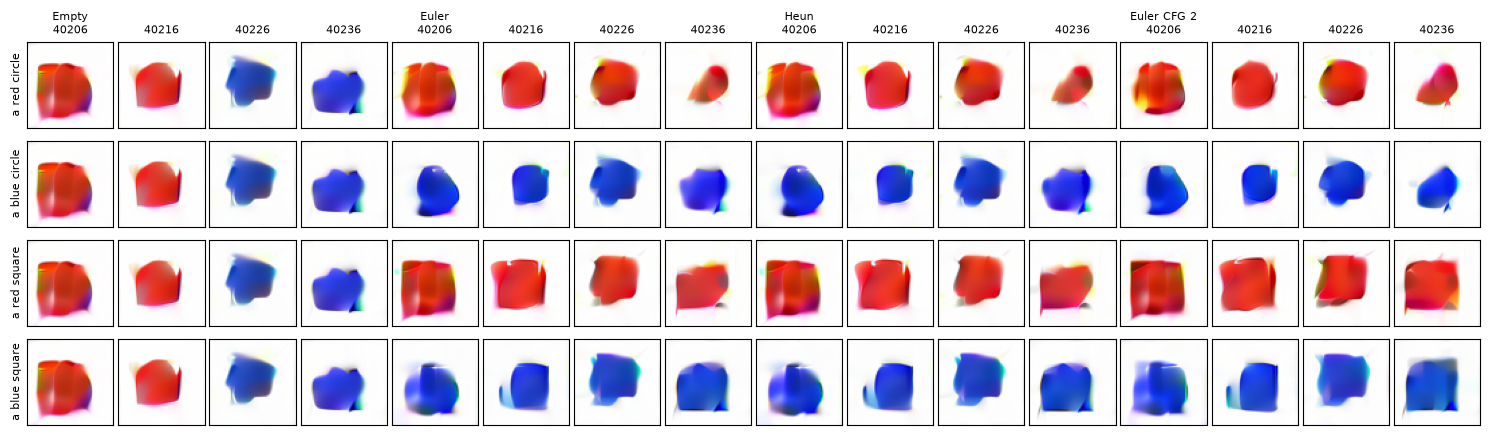

In [9]:
def classify_icon(
    image: Tensor,
) -> tuple[int, int]:
    """用彩色前景的主连通域估计颜色和形状；无法可靠解析返回 (-1,-1)。"""
    rgb = ((image.permute(1, 2, 0).numpy() + 1.0) / 2.0).clip(0, 1)
    red_minus_blue = rgb[..., 0] - rgb[..., 2]
    mask = np.abs(red_minus_blue) > 0.30
    count, objects, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )
    if count < 2:
        return -1, -1
    i = int(stats[1:, cv2.CC_STAT_AREA].argmax()) + 1
    _, _, w, h, area = stats[i]
    if area < 250 or area > 2200 or area < 0.90 * mask.sum() or not 0.70 < w / h < 1.43:
        return -1, -1
    fill = area / (w * h)
    if fill < 0.62:
        return -1, -1
    return int(red_minus_blue[objects == i].mean() < 0), int(fill > 0.89)


def report_scores(
    images: Tensor,
    labels: Tensor,
) -> str:
    """报告全分母的颜色、形状、同时命中和解析失败计数。"""
    answers = torch.tensor([classify_icon(x) for x in images])
    hits = answers == torch.stack([labels % 2, labels // 2], dim=1)
    colors, shapes = hits.sum(0).tolist()
    return (
        f"color={colors}/{len(labels)}, shape={shapes}/{len(labels)}, "
        f"both={hits.all(1).sum().item()}/{len(labels)}, "
        f"unparsed={(answers[:, 0] < 0).sum().item()}/{len(labels)}"
    )


assert classify_icon(torch.ones_like(val_x[0])) == (-1, -1)
# 同一规则先检查未见几何的原图和 VAE 重建，不用生成图改阈值。
val_recon = torch.cat([vae.decode(x) for x in val_z.split(8)])
print("held-out originals:", report_scores(val_x, val_y))
print("held-out VAE recon:", report_scores(val_recon, val_y))

seeds = [40206, 40216, 40226, 40236]
noise_bank = torch.cat(
    [torch.randn((1, 4, 8, 8), generator=torch.Generator().manual_seed(seed)) for seed in seeds]
)
starts = noise_bank.repeat((len(captions), 1, 1, 1))
prompt_ids = torch.arange(len(captions)).repeat_interleave(len(seeds))
settings = [
    ("Empty", 20, False, 0.0),
    ("Euler", 20, False, 1.0),
    ("Heun", 10, True, 1.0),
    ("Euler CFG 2", 10, False, 2.0),
]
pictures = []
for name, updates, heun, scale in settings:
    last_z, counts = sample_reference(model, starts, prompt_ids, updates, heun=heun, scale=scale)
    assert counts == (updates * (2 if heun else 1), 20, updates * (2 if heun else 1))
    if scale == 0:
        torch.testing.assert_close(last_z, last_z[: len(seeds)].repeat((4, 1, 1, 1)))
    outputs = torch.cat([vae.decode(x) for x in last_z.split(8)])
    assert torch.isfinite(outputs).all()
    pictures.append(outputs)
    predicted_shapes = torch.tensor([classify_icon(x)[1] for x in outputs])
    circle_hits = (predicted_shapes[prompt_ids < 2] == 0).sum().item()
    square_hits = (predicted_shapes[prompt_ids >= 2] == 1).sum().item()
    print(
        f"{name:12} updates={updates:2d}, (field, branch, forward)={counts}: "
        f"{report_scores(outputs, prompt_ids)} | circle {circle_hits}/8, square {square_hits}/8"
    )

# 每行一个 prompt，列按采样方案与 seed 排列。保留完整预登记网格。
fig, axes = plt.subplots(4, 16, figsize=(15, 4.5))
for j, (name, *_) in enumerate(settings):
    for row, label in enumerate(captions):
        for k, seed in enumerate(seeds):
            ax = axes[row, j * len(seeds) + k]
            rgb = pictures[j][row * len(seeds) + k]
            ax.imshow(((rgb.permute(1, 2, 0) + 1.0) / 2.0).clamp(0, 1))
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(f"{name}\n{seed}" if k == 0 else str(seed), fontsize=8)
            if j == 0 and k == 0:
                ax.set_ylabel(label, fontsize=8)
fig.tight_layout(w_pad=0.35)
plt.show()

### **3. 读结果时把颜色与形状分开**

- **固定拟合和随机训练回答了不同的问题。** 固定 8 图的 MSE 从 $3.06988$ 降到 $0.04474$。随机训练末步在三档时间上的正确条件 MSE 平均为 $0.8822$，比训练集高斯矩基线更低。正确条件留出 MSE 在 2160 步为 $0.8688$，末步略回升。训练 loss 持续降低的同时，留出误差已不单调下降，因此按预先定下的末步展示。带放回抽样的总量为 38,400，平均每张训练图期望被抽到 600 次。这个任务的数据复用很重，留出曲线提示继续加步数需要新证据。
- **模型对颜色词的响应强于形状词。** 在同一留出状态上只换颜色，末步 MSE 从 $0.8822$ 升到 $2.5740$。只换形状升到 $0.9516$。这个差距与输出速度的局部探针相符。由于正确图的中间状态已提供视觉信息，这组数值首先说明回归如何利用条件。
- **随机起点暴露了形状瓶颈。** 留出原图和 VAE 重建均为 $32/32$ 同时命中。单分支 Euler 和 Heun 的颜色都是 $16/16$，但在本规则下各只通过 $8/8$ 圆形和 $0/8$ 方形。画廊里可以看到方形边缘仍容易变圆，也有明显混色和轮廓不规则。Euler CFG 2 把联合通过从 $8/16$ 提到 $9/16$，同时出现一次解析失败。先把这种有限的形状遵循如实记录，再用更多样本和独立审阅定位模型与规则的各自误差。

这份输出来自一次最终记录的 CPU 训练。同配置的技术复跑用于确认闭环并补足换形状词和练习验收。各次使用相同训练种子，因此只计一个独立种子。

这组对照足以检查同一速度头能否训练、条件能否影响采样，以及求解器是否按设定预算调用。样本、提示和训练种子都很少，Euler 与 Heun 的生成质量差异要结合更大的冻结评测才有解释力。CFG 同时改变速度和允许的积分步数，等分支预算结果是两个完整采样方案的比较。

## **七、练手｜只写速度损失与最小采样循环**

### **1. 两个接口的输入和输出**

| 函数 | 输入 | 输出和检查 |
| --- | --- | --- |
| `flow_loss` | 同形预测与速度标签，形状 `[b,*z]` | FP32 标量 MSE，保留预测梯度。形状不一致抛出 `ValueError` |
| `sample_ode` | 一个 `field(state,time)`、初始张量、正整数步数 | 从 0 到 1 的均匀 Euler 终值和真实 NFE。步数非正抛出 `ValueError` |

建议合上前面的参考，从公式写起。将 DiT 与文本条件封装在 `field` 里，积分循环只处理「给定位置和时间，取一次速度」。验收不调用上面的参考函数。填好后一格运行检查。项目现有 [Flow 练习入口](src/minigen/objectives/flow_objective.py) 的 `velocity_loss` 对应本课的 `flow_loss`。最小 Euler 循环可以用该文件中预留的 `euler_step` 概念搭建。这里练的是这些契约，学习实现留在当前笔记。

In [ ]:
def flow_loss(
    predicted: Tensor,
    target: Tensor,
) -> Tensor:
    """个人练习：相同形状的速度做 FP32 MSE，拒绝隐式广播。"""
    raise NotImplementedError("flow_loss")


def sample_ode(
    field: Callable[[Tensor, float], Tensor],
    initial: Tensor,
    steps: int,
) -> tuple[Tensor, int]:
    """个人练习：均匀 Euler 从 t=0 积到 t=1，返回终值和 NFE。"""
    raise NotImplementedError("sample_ode")

### **2. 独立数值题与待完成状态**

损失题选了误差 $(1,2,-1,0)$，平方和为 $6$，MSE 为 $1.5$，梯度为误差的二分之一。采样题设速度场 $v(x,t)=t$，用四个左端点做 Euler，位移为 $(0+0.25+0.5+0.75)/4=0.375$。连续解析积分为 $0.5$，该练习的期望是离散 Euler 的值。这样既能检查时间方向，也能分辨偷偷用梯形求积或直接写终点答案的实现。

再用状态依赖场 $v(x,t)=x$，四步 Euler 每步乘 $1.25$，终值应为 $1.25^4 x_0$。这一题能识别每一步误用初始状态的实现。损失测试传入 FP64，以确认返回 FP32 是实现真的做了转换。

In [11]:
def check_flow_loss() -> None:
    """检查独立算出的损失、梯度、返回形状及广播拒绝。"""
    p = torch.tensor([[1.0, 3.0], [0.0, -1.0]], dtype=torch.float64, requires_grad=True)
    u = torch.tensor([[0.0, 1.0], [1.0, -1.0]], dtype=p.dtype)
    loss_value = flow_loss(p, u)
    assert loss_value.shape == () and loss_value.dtype == torch.float32
    torch.testing.assert_close(loss_value, torch.tensor(1.5))
    loss_value.backward()
    torch.testing.assert_close(p.grad, torch.tensor([[0.5, 1.0], [-0.5, 0.0]], dtype=p.dtype))
    try:
        flow_loss(p, u[:1])
    except ValueError:
        return
    raise AssertionError("mismatched shapes should raise ValueError")


def check_sample_ode() -> None:
    """在非自治场 v=t 上独立检查方向、采样时刻和 NFE。"""
    calls = []

    def clock_field(
        state: Tensor,
        time: float,
    ) -> Tensor:
        calls.append(time)
        return torch.full_like(state, time)

    start = torch.tensor([1.0, -2.0])
    end, nfe = sample_ode(clock_field, start, 4)
    assert calls == [0.0, 0.25, 0.5, 0.75] and nfe == 4
    torch.testing.assert_close(end, torch.tensor([1.375, -1.625]))
    torch.testing.assert_close(start, torch.tensor([1.0, -2.0]))

    def state_field(state: Tensor, time: float) -> Tensor:
        return state

    grown, nfe = sample_ode(state_field, start, 4)
    torch.testing.assert_close(grown, start * (1.25**4))
    assert nfe == 4
    try:
        sample_ode(clock_field, start, 0)
    except ValueError:
        return
    raise AssertionError("zero steps should raise ValueError")


for name, check in (("flow_loss", check_flow_loss), ("sample_ode", check_sample_ode)):
    try:
        check()
    except NotImplementedError:
        print(f"{name}: 待完成")
    else:
        print(f"{name}: 通过")

flow_loss: 待完成
sample_ode: 待完成


## **八、自测、审核范围与下一课**

<details>
<summary>1. 为什么训练使用冻结的 VAE，却还能改变生成出来的图像？</summary>

训练改变的是从噪声到干净 latent 的速度场。Decoder 的映射固定，但它收到的终点会改变，因此输出也改变。VAE 的重建质量给当前表示能力提供参照。

</details>

<details>
<summary>2. 为什么空文本需要 mask，不能把所有 token 都设成无效？</summary>

本课的空条件是同一个 CLIP 编码的 BOS/EOS，属于训练见过的条件。若所有位置都无效，注意力没有可归一的键，有的实现会产生 NaN，有的会输出零或均匀权重。三者都改变了条件定义。

</details>

<details>
<summary>3. 正确提示的回归误差较低，足以说模型生成出了正确形状吗？</summary>

回归测试给定了来自真实图的中间状态，采样必须从纯噪声开始。它要沿模型自己的状态分布反复积分。形状结论还需要同噪声换形状词、完整画廊和独立评分一起支持。

</details>

<details>
<summary>4. 为什么恢复测试还要比较下一批和 AdamW 动量？</summary>

模型参数相同只证明载入了一份权重。下一批、噪声、时间和丢弃条件要一致，优化器也需要此前的动量和计数，下一步参数才可能一致。本课显式 RNG 统一控制这些随机抽样。

</details>

| 验收项 | 证据 |
| --- | --- |
| 公式与张量 | 核对线性路径方向、时间广播、VAE 缩放、patch 往返、MSE 和 CFG 端点 |
| 教学运行 | 真实本地组件前向、固定监督拟合、随机训练、留出条件对照、完整采样 |
| 恢复 | 同一 CPU 后端的一步恢复逐项相等 |
| 个人实现 | 两个核心函数待填写。检查格能分别复验 |
| 正式 v2 | 学习示例限 64px 合成图。256px 单张仅用于组件与形状探针 |

下一课 S5-01 把这章的 `图像 query → 文本 key/value` 当作参照，比较 Self、Cross 与 Joint Attention 的信息流，再追踪 2D RoPE 怎样给图像 token 提供空间位置。[v2 学习目录](../MiniGen2学习目录.md)